In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec
import xarray as xr
import rioxarray as rxr
from pathlib import Path
from scipy.ndimage import gaussian_filter
from scipy.stats import sem
from scipy.io import loadmat
import h5py
import sys
sys.path.insert(0, "/home/jovyan/shared/Libraries/")
import victor
# Reproducibility
RNG = np.random.default_rng(seed=42)

# Output directory
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

<h2> 1. Baseline DEM & Flow Setup </h2>

Load your real DEM (or define a synthetic slope). All noise experiments perturb *this* baseline.

In [2]:
# --- Option A: Load real DEM ---
dem = rxr.open_rasterio("MaunaLoa.asc").sel(band=1)        # xarray DataArray or numpy array
dx = dem.rio.resolution()[0]               # horizontal resolution [m]

# --- Option B: Synthetic inclined plane (for controlled experiments) ---
Nx, Ny = dem.shape[0], dem.shape[1]         # grid cells
dx = 10.0                   # [m] — match your real DEM resolution
slope_deg = 5.0            # mean slope

x = np.arange(Nx) * dx
y = np.arange(Ny) * dx
X, Y = np.meshgrid(x, y, indexing='ij')

baseline_dem = -X * np.tan(np.radians(slope_deg))   # simple inclined plane [m]

print(f"DEM shape: {dem.shape}")
print(f"Elevation range: {dem.min():.1f} to {dem.max():.1f} m")

DEM shape: (1627, 2350)
Elevation range: 0.0 to 13674.0 m


In [3]:
dem.shape[0]

1627

<h2> 2. DEM Noise Generation </h2>

The paper uses uncorrelated (white) Gaussian vertical noise with std $\sigma_z$.  
We also test spatially correlated noise to see if it matters for flowDEM.

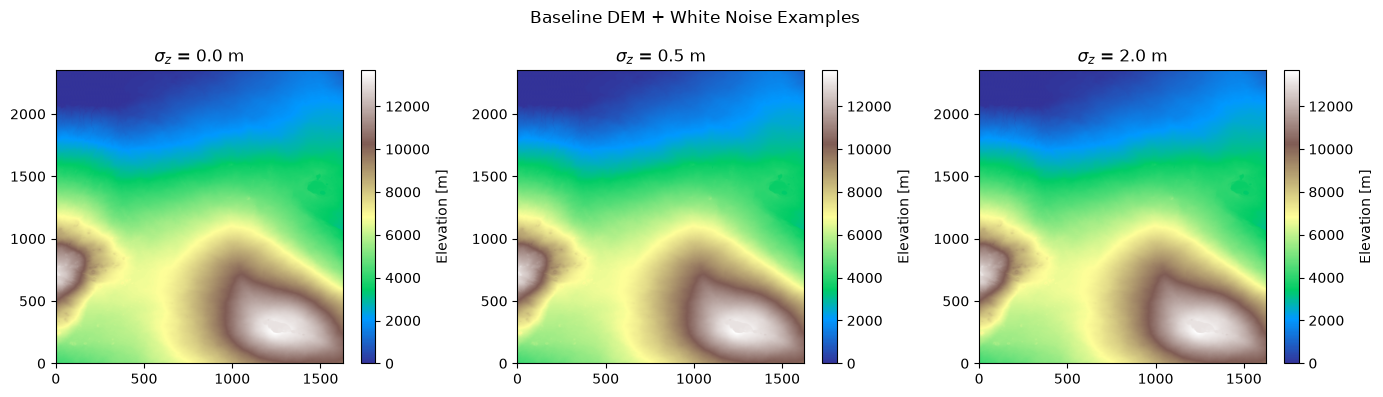

In [4]:
def add_white_noise(dem: np.ndarray, sigma_z: float, rng=RNG) -> np.ndarray:
    """Add uncorrelated Gaussian vertical noise (Roman 2025 baseline)."""
    return dem + rng.normal(0, sigma_z, dem.shape)


def add_correlated_noise(dem: np.ndarray, sigma_z: float,
                          corr_length_cells: float = 5.0, rng=RNG) -> np.ndarray:
    """Spatially correlated Gaussian noise (smoothed white noise)."""
    raw = rng.normal(0, 1, dem.shape)
    smoothed = gaussian_filter(raw, sigma=corr_length_cells)
    # Rescale to desired sigma_z
    smoothed = smoothed / smoothed.std() * sigma_z
    return dem + smoothed


# Quick visual sanity check
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
example_sigmas = [0.0, 0.5, 2.0]   # [m]
for ax, sig in zip(axes, example_sigmas):
    noisy = add_white_noise(dem, sig)
    im = ax.imshow(noisy.T, origin='lower', aspect='auto', cmap='terrain')
    ax.set_title(f"$\\sigma_z$ = {sig} m")
    plt.colorbar(im, ax=ax, label='Elevation [m]')
plt.suptitle("Baseline DEM + White Noise Examples")
plt.tight_layout()
plt.savefig(OUT_DIR / "dem_noise_examples.png", dpi=150)
plt.show()

<h2> 3. Key Dimensionless Parameter </h2>

Roman (2025) frames everything around:
$$\eta^* = \frac{\sigma_z}{h}$$
where $h$ is the characteristic flow thickness.  
The **critical threshold** is $\eta^* \approx 0.10$.

Set your expected flow thickness here.

In [5]:
# Characteristic flow thickness — set to your expected value
h_flow = 5.0    # [m]  (adjust per your eruption scenario)

# Define noise levels spanning sub-threshold to well above threshold
eta_star_values = np.array([0.01, 0.05, 0.10, 0.20, 0.30, 0.50, 1.00])
sigma_z_values  = eta_star_values * h_flow

print("eta*   | sigma_z [m]")
print("-" * 25)
for eta, sig in zip(eta_star_values, sigma_z_values):
    marker = "  <-- threshold" if abs(eta - 0.10) < 0.001 else ""
    print(f"{eta:.2f}   | {sig:.3f} m{marker}")

eta*   | sigma_z [m]
-------------------------
0.01   | 0.050 m
0.05   | 0.250 m
0.10   | 0.500 m  <-- threshold
0.20   | 1.000 m
0.30   | 1.500 m
0.50   | 2.500 m
1.00   | 5.000 m


<h2> 4. Noise Experiment Runner </h2>

For each $\sigma_z$, run $N_{\text{ensemble}}$ simulations with independent noise realizations and record flow-front position vs. time.

In [6]:
def flow_front_metrics(hsol_t, x, y, xs, ys, thresh=0.01, pct=95, width_pct=90):
    """
    Parameters
    ----------
    hsol_t    : (ny, nx) float — single time slice of flow thickness [m]
    x, y      : (nx,) and (ny,) float — coordinate vectors in vent-origin projection [m]
    xs, ys    : float — vent location [m]
    thresh    : float — minimum thickness to count as wet [m]
    pct       : float — percentile for advance distance (95 recommended)
    width_pct : float — percentile span for width (90 recommended)

    Returns
    -------
    dict with keys:
        max_extent    — furthest wet cell from vent [m]
        pct_extent    — pct-th percentile advance distance [m]  ← primary
        centroid_dist — thickness-weighted centroid distance [m]
        wetted_area   — total wet area [m²]
        width         — width_pct span perpendicular to flow axis [m]
        max_thickness — max h over wet cells [m]
        mean_thickness— mean h over wet cells [m]
    """
    wet = hsol_t > thresh                          # (ny, nx) bool mask

    X, Y = np.meshgrid(x, y)                      # (ny, nx)
    dx   = float(np.abs(x[1] - x[0]))             # cell size [m]

    # ── displacements from vent ──────────────────────────────────────────────
    dX = X - xs                                    # (ny, nx)
    dY = Y - ys

    dist = np.sqrt(dX**2 + dY**2)                 # distance from vent

    wet_dists = dist[wet]

    if wet_dists.size == 0:
        return dict(max_extent=0., pct_extent=0., centroid_dist=0.,
                    wetted_area=0., width=0.,
                    max_thickness=0., mean_thickness=0.)

    # ── advance metrics ──────────────────────────────────────────────────────
    max_extent    = float(wet_dists.max())
    pct_extent    = float(np.percentile(wet_dists, pct))

    h_wet = hsol_t[wet]

    # thickness-weighted centroid
    cx = float(np.average(X[wet], weights=h_wet)) - xs
    cy = float(np.average(Y[wet], weights=h_wet)) - ys
    centroid_dist = float(np.sqrt(cx**2 + cy**2))

    # ── width: perpendicular to vent→centroid axis ───────────────────────────
    # unit vector along flow axis (vent → centroid)
    axis_len = np.sqrt(cx**2 + cy**2)
    if axis_len < 1e-6:
        width = 0.0
    else:
        u_par  = np.array([cx, cy]) / axis_len    # unit vector along axis
        u_perp = np.array([-u_par[1], u_par[0]])  # unit vector perpendicular

        # scalar projection of each wet cell onto u_perp
        perp_proj = dX[wet] * u_perp[0] + dY[wet] * u_perp[1]  # (n_wet,)

        lo = np.percentile(perp_proj, (100 - width_pct) / 2)
        hi = np.percentile(perp_proj, 100 - (100 - width_pct) / 2)
        width = float(hi - lo)

    # ── thickness metrics ────────────────────────────────────────────────────
    return dict(
        max_extent     = max_extent,
        pct_extent     = pct_extent,
        centroid_dist  = centroid_dist,
        wetted_area    = float(wet.sum() * dx**2),
        width          = width,
        max_thickness  = float(h_wet.max()),
        mean_thickness = float(h_wet.mean()),
    )

In [9]:
N_ENSEMBLE = 10     # realisations per sigma_z level (increase for production runs)

results = {
    "sigma_z":        sigma_z_values,
    "eta_star":       eta_star_values,
    "advance_final":  np.full((len(sigma_z_values), N_ENSEMBLE), np.nan),
    "width_final":    np.full((len(sigma_z_values), N_ENSEMBLE), np.nan),
    "max_thickness":  np.full((len(sigma_z_values), N_ENSEMBLE), np.nan),
    "mean_thickness": np.full((len(sigma_z_values), N_ENSEMBLE), np.nan),
    # NOTE: no "advance_timeseries" anymore -- MOLASSES only gives us a final
    # footprint per run, not a time series, so Section 7 and Section 10 below
    # (which plotted/consumed time series) have been removed.
}

import rasterio
import subprocess
import os


def read_esri_ascii(path):
    """Parse a standard ESRI ASCII grid (6-line header + rows of values).

    Returns
    -------
    thickness : (nrows, ncols) float array, NODATA cells set to NaN
    x         : (ncols,) float array -- cell-center x coordinates
    y         : (nrows,) float array -- cell-center y coordinates,
                row 0 corresponds to the NORTHERNMOST row (matches the
                top-to-bottom row order the file is written in)
    """
    header = {}
    with open(path) as f:
        for _ in range(6):
            key, val = f.readline().split()
            header[key.lower()] = val
        data = np.loadtxt(f)

    ncols     = int(header["ncols"])
    nrows     = int(header["nrows"])
    cellsize  = float(header["cellsize"])
    nodata    = float(header.get("nodata_value", -9999))

    # corner keys vs. center keys -- handle either convention
    if "xllcorner" in header:
        xll = float(header["xllcorner"]) + cellsize / 2.0
        yll = float(header["yllcorner"]) + cellsize / 2.0
    else:
        xll = float(header["xllcenter"])
        yll = float(header["yllcenter"])

    data = data.reshape(nrows, ncols)
    thickness = np.where(data == nodata, np.nan, data)

    x = xll + cellsize * np.arange(ncols)
    y = yll + cellsize * (nrows - 1 - np.arange(nrows))   # row 0 = top = max y

    return thickness, x, y


BASELINE_ASC = Path("MaunaLoa.asc")   # baseline DEM, ESRI ASCII grid (MOLASSES' expected format)

with rasterio.open(BASELINE_ASC) as src:
    base_profile = src.profile.copy()

# MOLASSES writes an ASCII grid, so make sure we write noisy DEMs the same way
asc_profile = base_profile.copy()
asc_profile.update(driver="AAIGrid")

# --- fixed per-run settings: adjust these to your actual scenario ---
easting, northing = 254650, 2152400          # vent location, same coordinate frame as the DEM
volume = 1.0e7                      # [m^3] total erupted volume for every run in this sweep


def run_molasses(noisy_dem, run_id):
    """Write a noisy DEM, run one MOLASSES simulation, and return the final
    thickness footprint + its coordinate vectors."""
    dem_asc_name = f"noisy_dem_{run_id}.asc"
    with rasterio.open(Path(".") / dem_asc_name, "w", **asc_profile) as dst:
        dst.write(noisy_dem.astype(asc_profile["dtype"]), 1)

    with open("custom_molasses.conf", "r+") as f:
        conf = f.readlines()
        conf[2]  = "MIN_RESIDUAL = 1\n"
        conf[3]  = "MAX_RESIDUAL = 10\n"
        conf[4]  = f"MIN_TOTAL_VOLUME = {str(volume)}\n"
        conf[5]  = f"MAX_TOTAL_VOLUME = {str(volume)}\n"
        conf[6]  = f"MIN_PULSE_VOLUME = {float(volume) / 1000}\n"
        conf[7]  = f"MAX_PULSE_VOLUME = {float(volume) / 1000}\n"
        conf[10] = f"DEM_FILE = ./{dem_asc_name}\n"
        f.seek(0)
        f.writelines(conf)
        f.truncate()

    with open("events.in", "w") as f:
        f.write(f"{easting},{northing}")

    subprocess.run("./molasses_2022 custom_molasses.conf", shell=True, stderr=subprocess.DEVNULL)

    name = run_id  # <-- swap for however `name` is derived in your existing extraction code
    victor.convert_molasses(f"molasses_{name}", resolution=30)
    os.remove(f"molasses_{name}.asc.aux.xml")
    os.remove(f"molasses_{name}.prj")

    thickness, x_out, y_out = read_esri_ascii(f"molasses_{name}.asc")
    return thickness, x_out, y_out


for noise_idx, (eta, sig) in enumerate(zip(eta_star_values, sigma_z_values)):
    print(f"Running eta* = {eta:.2f}  (sigma_z = {sig:.3f} m)...")

    for j in range(N_ENSEMBLE):
        noisy_dem = add_white_noise(dem, sig)
        thickness, x_run, y_run = run_molasses(noisy_dem, run_id=f"{noise_idx}_{j}")

        m = flow_front_metrics(thickness, x_run, y_run, easting, northing)

        results["advance_final"][noise_idx, j]  = m["pct_extent"]
        results["width_final"][noise_idx, j]    = m["width"]
        results["max_thickness"][noise_idx, j]  = m["max_thickness"]
        results["mean_thickness"][noise_idx, j] = m["mean_thickness"]

    print(f"  → ensemble complete. mean advance = {results['advance_final'][noise_idx].mean():.1f} m")

print("Done.")


Running eta* = 0.01  (sigma_z = 0.050 m)...
Seeding random number generator: 1786045671


               MOLASSES is a lava flow simulator.

Config file: custom_molasses.conf
Reading in Parameters...
             PARENTS = 1                    [assigned]
    ELEVATION_UNCERT = 0                    [assigned]
        MIN_RESIDUAL = 1                    [assigned]
        MAX_RESIDUAL = 10                   [assigned]
    MIN_TOTAL_VOLUME = 10000000.0           [assigned]
    MAX_TOTAL_VOLUME = 10000000.0           [assigned]
    MIN_PULSE_VOLUME = 10000.0              [assigned]
    MAX_PULSE_VOLUME = 10000.0              [assigned]
                RUNS = 1                    [assigned]
      ASCII_FLOW_MAP = 1                    [assigned]
            DEM_FILE = ./noisy_dem_0_0.asc  [assigned]
         EVENTS_FILE = events.in            [assigned]
Nothing missing.

DEM Information [Arc/Info ASCII Grid]:
  File:              ./noisy_dem_0_0.asc
  Lower Left Origin: (219135.000000,214399

NameError: name 'victor' is not defined

---
## 5. Effect of Noise on Flow Advance

Reproduce Fig. 2 analog from Roman (2025): advance rate vs. $\eta^*$.

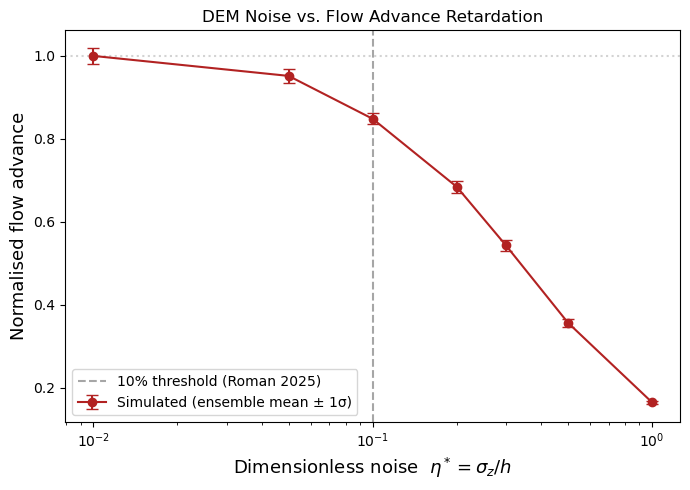

In [6]:
advance_mean = results["advance_final"].mean(axis=1)
advance_std  = results["advance_final"].std(axis=1)

# Normalise to noise-free (eta* = 0) baseline
advance_norm = advance_mean / advance_mean[0]
advance_std_norm = advance_std / advance_mean[0]

fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(eta_star_values, advance_norm, yerr=advance_std_norm,
            fmt='o-', capsize=4, color='firebrick', label='Simulated (ensemble mean ± 1σ)')
ax.axvline(0.10, color='gray', linestyle='--', alpha=0.7, label='10% threshold (Roman 2025)')
ax.axhline(1.0,  color='lightgray', linestyle=':')
ax.set_xlabel(r"Dimensionless noise  $\eta^* = \sigma_z / h$", fontsize=13)
ax.set_ylabel("Normalised flow advance", fontsize=13)
ax.set_xscale('log')
ax.set_title("DEM Noise vs. Flow Advance Retardation")
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "advance_vs_noise.png", dpi=150)
plt.show()

---
## 6. Effect of Noise on Flow Width and Thickness

In [ ]:
width_mean = results["width_final"].mean(axis=1)
width_std  = results["width_final"].std(axis=1)
thick_mean = results["mean_thickness"].mean(axis=1)
thick_std  = results["mean_thickness"].std(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y, yerr, label, color in zip(
    axes,
    [width_mean / width_mean[0], thick_mean / thick_mean[0]],
    [width_std  / width_mean[0], thick_std  / thick_mean[0]],
    ["Normalised mean width", "Normalised mean thickness"],
    ["steelblue", "seagreen"]
):
    ax.errorbar(eta_star_values, y, yerr=yerr, fmt='s-', capsize=4, color=color)
    ax.axvline(0.10, color='gray', linestyle='--', alpha=0.7)
    ax.axhline(1.0, color='lightgray', linestyle=':')
    ax.set_xlabel(r"$\eta^* = \sigma_z / h$", fontsize=12)
    ax.set_ylabel(label, fontsize=12)
    ax.set_xscale('log')
    ax.set_title(label)

plt.suptitle("Noise Effect on Flow Geometry (normalised to zero-noise baseline)", fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR / "geometry_vs_noise.png", dpi=150)
plt.show()

---
## 8. Effusion Rate Retrieval Error

Roman (2025) shows that noise corrupts *inversion* of effusion rate from observed flow geometry.  
Here we estimate how well we can recover $Q$ from noisy-DEM simulations.

**Method:** Run forward model with known $Q_\text{true}$, add DEM noise, invert for $Q_\text{retrieved}$.

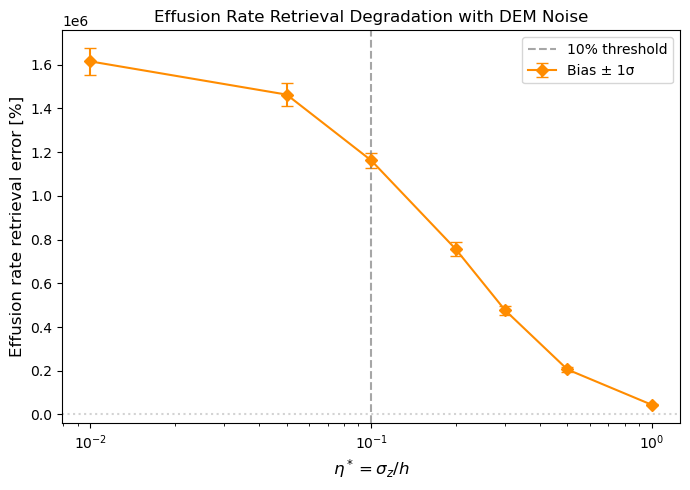

In [9]:
Q_true = 10.0   # [m³/s] — your target effusion rate

# --- Placeholder: invert Q from advance (replace with your actual inversion) ---
# Assumes advance ~ C * Q^alpha, so Q_retrieved = (advance / C)^(1/alpha)
C, alpha = 0.5, 0.5
Q_retrieved = np.full_like(results["advance_final"], np.nan)
for i in range(len(sigma_z_values)):
    Q_retrieved[i, :] = (results["advance_final"][i, :] / C) ** (1.0 / alpha)
# ---------------------------------------------------------------------------------

Q_error_pct = (Q_retrieved - Q_true) / Q_true * 100.0
Q_bias = Q_error_pct.mean(axis=1)
Q_spread = Q_error_pct.std(axis=1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(eta_star_values, Q_bias, yerr=Q_spread,
            fmt='D-', capsize=4, color='darkorange', label='Bias ± 1σ')
ax.axhline(0,    color='lightgray', linestyle=':')
ax.axvline(0.10, color='gray', linestyle='--', alpha=0.7, label='10% threshold')
ax.set_xlabel(r"$\eta^* = \sigma_z / h$", fontsize=12)
ax.set_ylabel("Effusion rate retrieval error [%]", fontsize=12)
ax.set_xscale('log')
ax.set_title("Effusion Rate Retrieval Degradation with DEM Noise")
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "effusion_rate_error.png", dpi=150)
plt.show()

---
## 9. Spatial Sampling Effects

Coarsen the DEM by averaging to larger cell sizes and re-run the simulation.  
Measures how horizontal resolution interacts with the noise threshold.

In [ ]:
from scipy.ndimage import uniform_filter

def coarsen_dem(dem: np.ndarray, factor: int) -> np.ndarray:
    """Block-average coarsening by integer factor."""
    nx = (dem.shape[0] // factor) * factor
    ny = (dem.shape[1] // factor) * factor
    d = dem[:nx, :ny].reshape(nx // factor, factor, ny // factor, factor)
    return d.mean(axis=(1, 3))


coarsen_factors = [1, 2, 4, 8, 16]   # multiples of baseline dx
resolutions_m   = [dx * f for f in coarsen_factors]

# Fixed moderate noise for this sweep
sigma_fixed = 0.1 * h_flow   # right at the 10% threshold

coarsen_advance = []
for f in coarsen_factors:
    coarse_dem   = coarsen_dem(dem, f)
    noisy_coarse = add_white_noise(coarse_dem, sigma_fixed)

    thickness, x_run, y_run = run_molasses(noisy_coarse, run_id=f"coarsen_{f}")
    m = flow_front_metrics(thickness, x_run, y_run, easting, northing)

    coarsen_advance.append(m["pct_extent"])

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(resolutions_m, np.array(coarsen_advance) / coarsen_advance[0],
        'o-', color='teal')
ax.set_xlabel("DEM horizontal resolution [m]", fontsize=12)
ax.set_ylabel("Normalised flow advance", fontsize=12)
ax.set_xscale('log')
ax.set_title(f"Spatial Resolution Effect (fixed $\\sigma_z$ = {sigma_fixed:.2f} m)")
plt.tight_layout()
plt.savefig(OUT_DIR / "spatial_sampling_effect.png", dpi=150)
plt.show()


---
## 11. Summary: Noise Threshold Map

2-D heatmap of normalised advance degradation as a function of *both* $\sigma_z$ and $h$.  
Useful for identifying which DEM products are adequate for a given eruption scenario.

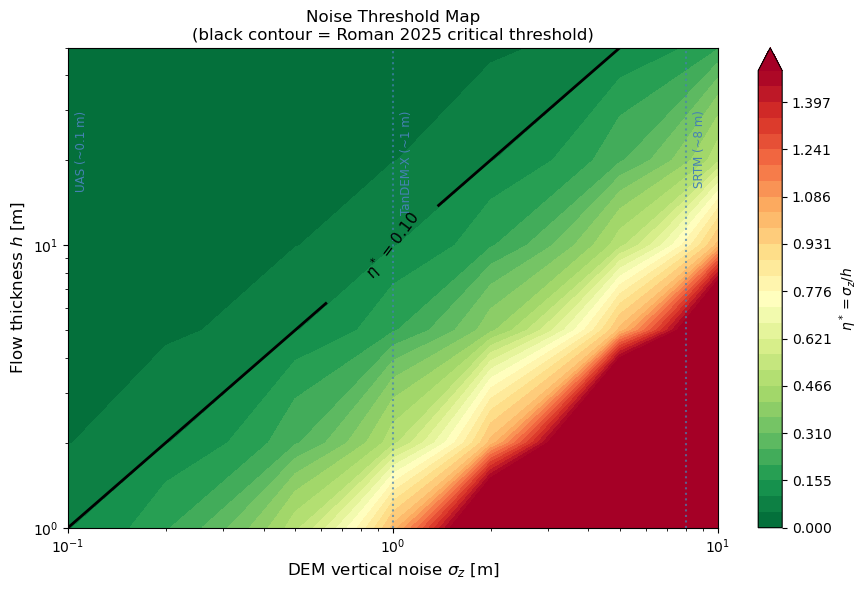

In [12]:
h_values     = np.array([1, 2, 5, 10, 20, 50])      # [m] possible flow thicknesses
sigma_values = np.array([0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0])  # [m] DEM vertical noise

# eta* grid
H, S = np.meshgrid(h_values, sigma_values, indexing='ij')
ETA  = S / H

fig, ax = plt.subplots(figsize=(9, 6))
levels = np.linspace(0, 1.5, 30)
cf = ax.contourf(sigma_values, h_values, ETA, levels=levels,
                 cmap='RdYlGn_r', extend='max')
cs = ax.contour(sigma_values, h_values, ETA, levels=[0.10],
                colors='black', linewidths=2.0)
ax.clabel(cs, fmt=r"$\eta^*$ = 0.10", fontsize=11)

plt.colorbar(cf, ax=ax, label=r"$\eta^* = \sigma_z / h$")
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r"DEM vertical noise $\sigma_z$ [m]", fontsize=12)
ax.set_ylabel(r"Flow thickness $h$ [m]", fontsize=12)
ax.set_title("Noise Threshold Map\n(black contour = Roman 2025 critical threshold)")

# Annotate with common DEM products
dem_products = {
    "SRTM (~8 m)": (8.0, None),
    "TanDEM-X (~1 m)": (1.0, None),
    "UAS (~0.1 m)": (0.1, None),
}
for label, (sig, _) in dem_products.items():
    ax.axvline(sig, color='steelblue', linestyle=':', alpha=0.7)
    ax.text(sig * 1.05, h_values[-1] * 0.6, label, fontsize=8.5,
            color='steelblue', rotation=90, va='top')

plt.tight_layout()
plt.savefig(OUT_DIR / "noise_threshold_map.png", dpi=150)
plt.show()

---
## 12. Correlated vs. White Noise Comparison

The paper assumes white noise. This cell tests whether spatial correlation length changes the threshold for flowDEM.

In [ ]:
corr_lengths = [0, 2, 5, 10, 20]   # [cells] -- 0 = white noise
test_sigma   = 0.1 * h_flow         # fixed at 10% threshold

corr_advance = []
for cl in corr_lengths:
    if cl == 0:
        noisy = add_white_noise(dem, test_sigma)
    else:
        noisy = add_correlated_noise(dem, test_sigma, corr_length_cells=cl)

    thickness, x_run, y_run = run_molasses(noisy, run_id=f"corr_{cl}")
    m = flow_front_metrics(thickness, x_run, y_run, easting, northing)

    corr_advance.append(m["pct_extent"])

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([cl * dx for cl in corr_lengths], np.array(corr_advance) / corr_advance[0],
        'o-', color='crimson')
ax.set_xlabel("Noise correlation length [m]", fontsize=12)
ax.set_ylabel("Normalised flow advance", fontsize=12)
ax.set_title(f"White vs. Correlated Noise ($\\sigma_z$ = {test_sigma:.2f} m fixed)\n"
             "0 m = white (Roman 2025 assumption)")
plt.tight_layout()
plt.savefig(OUT_DIR / "correlated_vs_white_noise.png", dpi=150)
plt.show()
